In [ ]:
# Step 1: Configure the MLflow server and credentials used to track the analysis. Do not commit real passwords.

MLFLOW_SERVER = "http://10.0.100.20:5000"
MLFLOW_USERNAME = "username"
MLFLOW_PASSWORD = "password"

In [2]:
# Step 2: Connect to MLflow and confirm the experiment is accessible before logging results.

import os
import requests
import mlflow

os.environ["MLFLOW_TRACKING_URI"] = MLFLOW_SERVER
os.environ["MLFLOW_TRACKING_USERNAME"] = MLFLOW_USERNAME
os.environ["MLFLOW_TRACKING_PASSWORD"] = MLFLOW_PASSWORD

mlflow.set_tracking_uri(MLFLOW_SERVER)

reply = requests.get(
    MLFLOW_SERVER + "/api/2.0/mlflow/experiments/search",
    params={"max_results": 1},
    auth=(MLFLOW_USERNAME, MLFLOW_PASSWORD),
    timeout=10
)

print("Server response:", reply.status_code)

if reply.status_code == 200:
    EXPERIMENT = f"Group1-Climate-Energy-{MLFLOW_USERNAME}"
    mlflow.set_experiment(EXPERIMENT)
    print("Connected successfully!")
    print("Experiment:", EXPERIMENT)
elif reply.status_code == 401:
    print("Incorrect username or password")
elif reply.status_code == 403:
    print("Account does not have permission")
else:
    print("Server returned:", reply.status_code)

Server response: 200
Connected successfully!
Experiment: Group1-Climate-Energy-csc-4933-001-user03


In [3]:
# Step 3: Locate the cleaned datasets so later analysis uses the same project data folder.

import pandas as pd
from pathlib import Path

# Data folder
data_path = Path.cwd() / "data"

# Cleaned datasets
datasets = {
    "Hourly Grid and Weather": "combined_hourly_clean.csv",
    "Daily Grid and Weather": "combined_daily_averages.csv",
    "Charging Sessions": "charging_sessions_clean.csv",
    "Home Charging": "home_charging_clean.csv",
    "Public Charging": "public_charging_clean.csv",
    "Vehicles": "vehicles_clean.csv",
    "Stations": "stations_clean.csv",
}

print("Data folder:", data_path)
print("Folder exists:", data_path.exists())

for name, filename in datasets.items():
    file_path = data_path / filename

    if file_path.exists():
        df = pd.read_csv(file_path, nrows=5)
        print(f"\n{name}")
        print("Columns:", list(df.columns))
    else:
        print(f"\nMissing: {filename}")

Data folder: c:\Users\Jason\Desktop\Group1-491\Topic3_Climate_Energy_The_Green_Tech_Carbon_Spike\data
Folder exists: True

Hourly Grid and Weather
Columns: ['utc_time_at_end_of_hour', 'balancing_authority', 'demand_forecast_mwh', 'demand_mwh', 'net_generation', 'total_interchange', 'coal', 'natural_gas', 'nuclear', 'wind', 'solar', 'hydro', 'other', 'unit', 'grid_utc', 'timestamp', 'station_id', 'temp_f', 'heating_degree_hours', 'wind_speed_mph', 'relative_humidity', 'local_time', 'weather_utc', 'matching_utc', 'date']

Daily Grid and Weather
Columns: ['date', 'demand_mwh', 'demand_forecast_mwh', 'net_generation', 'coal', 'natural_gas', 'nuclear', 'wind', 'solar', 'hydro', 'other', 'temp_f', 'heating_degree_hours', 'wind_speed_mph', 'relative_humidity', 'hours_recorded']

Charging Sessions
Columns: ['session_id', 'vehicle_id', 'station_id', 'port_type', 'connector', 'start_time', 'end_time', 'kwh', 'home_or_public']

Home Charging
Columns: ['session_id', 'vehicle_id', 'station_id', 'po

In [4]:
# Step 4: Load the hourly grid and daily weather datasets for the three research questions.

# Load cleaned grid and weather datasets
hourly = pd.read_csv(data_path / "combined_hourly_clean.csv")
daily = pd.read_csv(data_path / "combined_daily_averages.csv")

# Check dataset sizes
print("Hourly records:", len(hourly))
print("Daily records:", len(daily))

# Display column names and data types
print("\nHourly dataset:")
print(hourly.dtypes)

print("\nDaily dataset:")
print(daily.dtypes)

# Preview daily data
display(daily.head())

Hourly records: 17520
Daily records: 730

Hourly dataset:
utc_time_at_end_of_hour        str
balancing_authority            str
demand_forecast_mwh          int64
demand_mwh                   int64
net_generation             float64
total_interchange          float64
coal                       float64
natural_gas                float64
nuclear                    float64
wind                       float64
solar                      float64
hydro                      float64
other                      float64
unit                           str
grid_utc                       str
timestamp                      str
station_id                     str
temp_f                     float64
heating_degree_hours       float64
wind_speed_mph               int64
relative_humidity            int64
local_time                     str
weather_utc                    str
matching_utc                   str
date                           str
dtype: object

Daily dataset:
date                        str
deman

,date,demand_mwh,demand_forecast_mwh,net_generation,coal,natural_gas,nuclear,wind,solar,hydro,other,temp_f,heating_degree_hours,wind_speed_mph,relative_humidity,hours_recorded
0,2022-01-01,743.625000,743.958333,743.625000,302.708333,93.333333,210.083333,65.291667,10.458333,51.791667,9.958333,43.691667,21.308333,6.416667,76.625000,24
1,2022-01-02,741.583333,743.333333,741.625000,333.833333,94.583333,209.708333,29.083333,12.083333,52.333333,10.000000,43.258333,21.741667,6.000000,78.333333,24
2,2022-01-03,863.083333,863.875000,862.958333,396.333333,165.291667,210.208333,17.416667,10.625000,53.166667,9.916667,38.054167,26.945833,8.583333,82.166667,24
3,2022-01-04,823.166667,821.541667,823.416667,342.625000,108.000000,210.041667,88.708333,11.916667,52.000000,10.125000,42.395833,22.604167,11.750000,78.250000,24
4,2022-01-05,791.458333,786.625000,791.500000,351.833333,103.208333,210.041667,51.583333,12.250000,52.625000,9.958333,44.670833,20.329167,7.916667,76.916667,24


In [5]:
# Step 5: Inspect hourly fields to identify the measurements and units available.

# Inspect columns and units used for emissions calculations

print("HOURLY DATA COLUMNS")
for column in hourly.columns:
    print(column)

print("\nDAILY DATA COLUMNS")
for column in daily.columns:
    print(column)

print("\nSAMPLE HOURLY DATA")
display(hourly.head(3))

HOURLY DATA COLUMNS
utc_time_at_end_of_hour
balancing_authority
demand_forecast_mwh
demand_mwh
net_generation
total_interchange
coal
natural_gas
nuclear
wind
solar
hydro
other
unit
grid_utc
timestamp
station_id
temp_f
heating_degree_hours
wind_speed_mph
relative_humidity
local_time
weather_utc
matching_utc
date

DAILY DATA COLUMNS
date
demand_mwh
demand_forecast_mwh
net_generation
coal
natural_gas
nuclear
wind
solar
hydro
other
temp_f
heating_degree_hours
wind_speed_mph
relative_humidity
hours_recorded

SAMPLE HOURLY DATA


,utc_time_at_end_of_hour,balancing_authority,demand_forecast_mwh,demand_mwh,net_generation,total_interchange,coal,natural_gas,nuclear,wind,...,timestamp,station_id,temp_f,heating_degree_hours,wind_speed_mph,relative_humidity,local_time,weather_utc,matching_utc,date
0,2022-01-01 07:00,MCPA,634,643,643.0,0.0,284.0,0.0,211.0,106.0,...,2022-01-01 00:00,WX-0417,40.1,24.9,5,72,2022-01-01 00:00:00,2022-01-01 06:00:00+00:00,2022-01-01 07:00:00+00:00,2022-01-01
1,2022-01-01 08:00,MCPA,633,642,642.0,0.0,282.0,0.0,210.0,106.0,...,2022-01-01 01:00,WX-0417,38.1,26.9,4,83,2022-01-01 01:00:00,2022-01-01 07:00:00+00:00,2022-01-01 08:00:00+00:00,2022-01-01
2,2022-01-01 09:00,MCPA,639,641,640.0,0.0,286.0,0.0,209.0,106.0,...,2022-01-01 02:00,WX-0417,36.9,28.1,4,88,2022-01-01 02:00:00,2022-01-01 08:00:00+00:00,2022-01-01 09:00:00+00:00,2022-01-01


In [6]:
# Step 6: Find columns relevant to electricity generation, demand, and dates.

# Identify columns related to emissions, demand, and dates

keywords = ["emission", "carbon", "co2", "demand", "load", "generation", "date", "time"]

for name, df in [("Hourly", hourly), ("Daily", daily)]:
    print(f"\n{name} dataset:")

    matching = [
        col for col in df.columns
        if any(word in col.lower() for word in keywords)
    ]

    print("Relevant columns:", matching)

    if matching:
        display(df[matching].head(3))


Hourly dataset:
Relevant columns: ['utc_time_at_end_of_hour', 'demand_forecast_mwh', 'demand_mwh', 'net_generation', 'timestamp', 'local_time', 'date']


,utc_time_at_end_of_hour,demand_forecast_mwh,demand_mwh,net_generation,timestamp,local_time,date
0,2022-01-01 07:00,634,643,643.0,2022-01-01 00:00,2022-01-01 00:00:00,2022-01-01
1,2022-01-01 08:00,633,642,642.0,2022-01-01 01:00,2022-01-01 01:00:00,2022-01-01
2,2022-01-01 09:00,639,641,640.0,2022-01-01 02:00,2022-01-01 02:00:00,2022-01-01



Daily dataset:
Relevant columns: ['date', 'demand_mwh', 'demand_forecast_mwh', 'net_generation']


,date,demand_mwh,demand_forecast_mwh,net_generation
0,2022-01-01,743.625000,743.958333,743.625000
1,2022-01-02,741.583333,743.333333,741.625000
2,2022-01-03,863.083333,863.875000,862.958333


In [7]:
# Step 7: Preview the daily data and its summary statistics before using it in calculations.

# Find relevant columns
print("Available columns:")
print(daily.columns.tolist())

# Preview the first few rows
display(daily.head())

# Show summary statistics
display(daily.describe(include="all").T)

Available columns:
['date', 'demand_mwh', 'demand_forecast_mwh', 'net_generation', 'coal', 'natural_gas', 'nuclear', 'wind', 'solar', 'hydro', 'other', 'temp_f', 'heating_degree_hours', 'wind_speed_mph', 'relative_humidity', 'hours_recorded']


,date,demand_mwh,demand_forecast_mwh,net_generation,coal,natural_gas,nuclear,wind,solar,hydro,other,temp_f,heating_degree_hours,wind_speed_mph,relative_humidity,hours_recorded
0,2022-01-01,743.625000,743.958333,743.625000,302.708333,93.333333,210.083333,65.291667,10.458333,51.791667,9.958333,43.691667,21.308333,6.416667,76.625000,24
1,2022-01-02,741.583333,743.333333,741.625000,333.833333,94.583333,209.708333,29.083333,12.083333,52.333333,10.000000,43.258333,21.741667,6.000000,78.333333,24
2,2022-01-03,863.083333,863.875000,862.958333,396.333333,165.291667,210.208333,17.416667,10.625000,53.166667,9.916667,38.054167,26.945833,8.583333,82.166667,24
3,2022-01-04,823.166667,821.541667,823.416667,342.625000,108.000000,210.041667,88.708333,11.916667,52.000000,10.125000,42.395833,22.604167,11.750000,78.250000,24
4,2022-01-05,791.458333,786.625000,791.500000,351.833333,103.208333,210.041667,51.583333,12.250000,52.625000,9.958333,44.670833,20.329167,7.916667,76.916667,24


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,730,730,2022-01-01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
demand_mwh,730.0,NaN,NaN,NaN,744.825725,96.815296,556.583333,670.916667,735.5625,802.864583,1170.625
demand_forecast_mwh,730.0,NaN,NaN,NaN,744.751658,96.741395,553.416667,669.479167,734.75,801.104167,1164.375
net_generation,730.0,NaN,NaN,NaN,744.086777,94.259789,556.833333,671.052083,735.604167,802.197917,1122.0
coal,730.0,NaN,NaN,NaN,309.863202,56.179766,173.541667,271.770833,313.229167,350.520833,400.0
natural_gas,730.0,NaN,NaN,NaN,109.676389,53.11109,5.0,85.0,94.5625,127.041667,381.541667
nuclear,730.0,NaN,NaN,NaN,201.373253,28.861957,104.75,209.833333,209.958333,210.125,210.625
wind,730.0,NaN,NaN,NaN,41.444178,27.473886,0.0,19.34375,36.458333,60.385417,106.0
solar,730.0,NaN,NaN,NaN,21.447741,8.333002,5.416667,13.62875,21.083333,28.5,37.583333
hydro,730.0,NaN,NaN,NaN,50.285667,2.91467,45.5,47.5,50.270833,53.083333,55.916667


In [8]:
# Step 8: Load fuel-specific emission factors needed to estimate CO2 from generation.

# Load carbon emissions factors
fuel_factors = pd.read_csv(data_path / "fuel_factors.csv")

print("Fuel factors:")
display(fuel_factors)

print("\nColumn names:")
print(fuel_factors.columns.tolist())

Fuel factors:


,fuel,kg_co2_per_mwh,note
0,coal,1010.0,fleet average of the BA's coal units
1,natural_gas,430.0,fleet average of the BA's gas units (combined ...
2,nuclear,0.0,no stack emissions
3,wind,0.0,no stack emissions
4,solar,0.0,no stack emissions
5,hydro,0.0,no stack emissions
6,other,0.0,"landfill gas and biomass; biogenic, counted as..."
7,imports,520.0,average of the neighbouring balancing authorit...



Column names:
['fuel', 'kg_co2_per_mwh', 'note']


In [9]:
# Step 9: Inspect the fuel-factor fields to ensure the values can be mapped to fuel types.

# Check the structure of the fuel factors dataset
print("Fuel factor columns:")
print(fuel_factors.columns.tolist())

print("\nFuel factor data:")
print(fuel_factors.to_string(index=False))

Fuel factor columns:
['fuel', 'kg_co2_per_mwh', 'note']

Fuel factor data:
       fuel  kg_co2_per_mwh                                                                         note
       coal          1010.0                                         fleet average of the BA's coal units
natural_gas           430.0 fleet average of the BA's gas units (combined cycle and combustion turbines)
    nuclear             0.0                                                           no stack emissions
       wind             0.0                                                           no stack emissions
      solar             0.0                                                           no stack emissions
      hydro             0.0                                                           no stack emissions
      other             0.0       landfill gas and biomass; biogenic, counted as 0 in the city inventory
    imports           520.0      average of the neighbouring balancing authorities th

In [10]:
# Step 10: Check the fuel-factor table again before applying the emission calculation.

# Check fuel factor structure before calculating emissions
print("Fuel factor columns:", fuel_factors.columns.tolist())
display(fuel_factors)

# Check generation columns
generation_columns = [
    "coal", "natural_gas", "nuclear",
    "wind", "solar", "hydro", "other"
]

print("\nGeneration columns available:")
print([col for col in generation_columns if col in hourly.columns])

# Check hourly data
display(hourly[["date"] + [
    col for col in generation_columns if col in hourly.columns
]].head())

Fuel factor columns: ['fuel', 'kg_co2_per_mwh', 'note']


,fuel,kg_co2_per_mwh,note
0,coal,1010.0,fleet average of the BA's coal units
1,natural_gas,430.0,fleet average of the BA's gas units (combined ...
2,nuclear,0.0,no stack emissions
3,wind,0.0,no stack emissions
4,solar,0.0,no stack emissions
5,hydro,0.0,no stack emissions
6,other,0.0,"landfill gas and biomass; biogenic, counted as..."
7,imports,520.0,average of the neighbouring balancing authorit...



Generation columns available:
['coal', 'natural_gas', 'nuclear', 'wind', 'solar', 'hydro', 'other']


,date,coal,natural_gas,nuclear,wind,solar,hydro,other
0,2022-01-01,284.0,0.0,211.0,106.0,0.0,32.0,10.0
1,2022-01-01,282.0,0.0,210.0,106.0,0.0,34.0,10.0
2,2022-01-01,286.0,0.0,209.0,106.0,0.0,30.0,9.0
3,2022-01-01,302.0,0.0,210.0,94.0,0.0,30.0,10.0
4,2022-01-01,332.0,0.0,211.0,73.0,0.0,28.0,10.0


In [11]:
# Step 11: Estimate hourly and annual generation CO2 emissions to compare 2022 with 2023; imports are excluded.

# Calculate estimated hourly carbon emissions
# Generation values are treated as MW averaged over one-hour intervals

emission_factors = fuel_factors.set_index("fuel")["kg_co2_per_mwh"]

generation_columns = [
    "coal", "natural_gas", "nuclear",
    "wind", "solar", "hydro", "other"
]

# Convert each hourly generation value to estimated emissions
hourly["estimated_co2_kg"] = sum(
    hourly[fuel] * emission_factors[fuel]
    for fuel in generation_columns
)

# Extract year
hourly["year"] = pd.to_datetime(hourly["date"]).dt.year

# Sum hourly emissions by year
yearly_emissions = hourly.groupby("year")["estimated_co2_kg"].sum()

# Convert kg to metric tons
yearly_emissions_tons = yearly_emissions / 1000

print("Estimated annual generation emissions (metric tons CO2):")
print(yearly_emissions_tons)

# Calculate percentage change
change = (
    (yearly_emissions_tons.loc[2023] -
     yearly_emissions_tons.loc[2022])
    / yearly_emissions_tons.loc[2022]
) * 100

print(f"\n2022 to 2023 change: {change:.2f}%")

Estimated annual generation emissions (metric tons CO2):
year
2022    3061445.31
2023    3247827.48
Name: estimated_co2_kg, dtype: float64

2022 to 2023 change: 6.09%


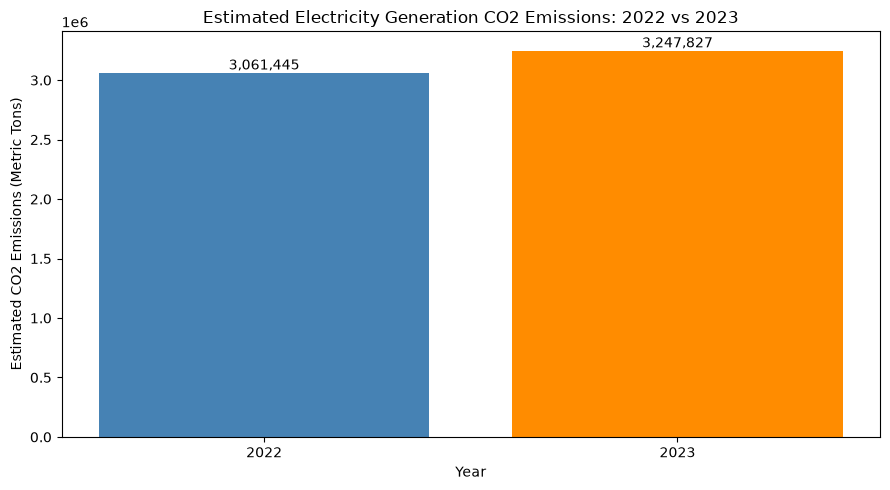

Graph and metrics logged to MLflow!
🏃 View run R3_2022_vs_2023_Emissions at: http://10.0.100.20:5000/#/experiments/91/runs/cb635f907c334f79947e97739986d066
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/91


In [12]:
# Step 12: Plot annual emissions and save the chart and totals in MLflow for research question 1.

import matplotlib.pyplot as plt
import mlflow

# Create bar chart
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    yearly_emissions_tons.index.astype(str),
    yearly_emissions_tons.values,
    color=["steelblue", "darkorange"]
)

ax.set_title("Estimated Electricity Generation CO2 Emissions: 2022 vs 2023")
ax.set_xlabel("Year")
ax.set_ylabel("Estimated CO2 Emissions (Metric Tons)")

# Display values above bars
for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
display(fig)

# Log graph and metrics to MLflow
with mlflow.start_run(run_name="R3_2022_vs_2023_Emissions"):
    mlflow.log_metric("emissions_2022_tons", float(yearly_emissions_tons.loc[2022]))
    mlflow.log_metric("emissions_2023_tons", float(yearly_emissions_tons.loc[2023]))
    mlflow.log_metric("emissions_percent_change", float(change))

    mlflow.log_figure(
        fig,
        "visualizations/yearly_emissions_comparison.png"
    )

    print("Graph and metrics logged to MLflow!")

plt.close(fig)

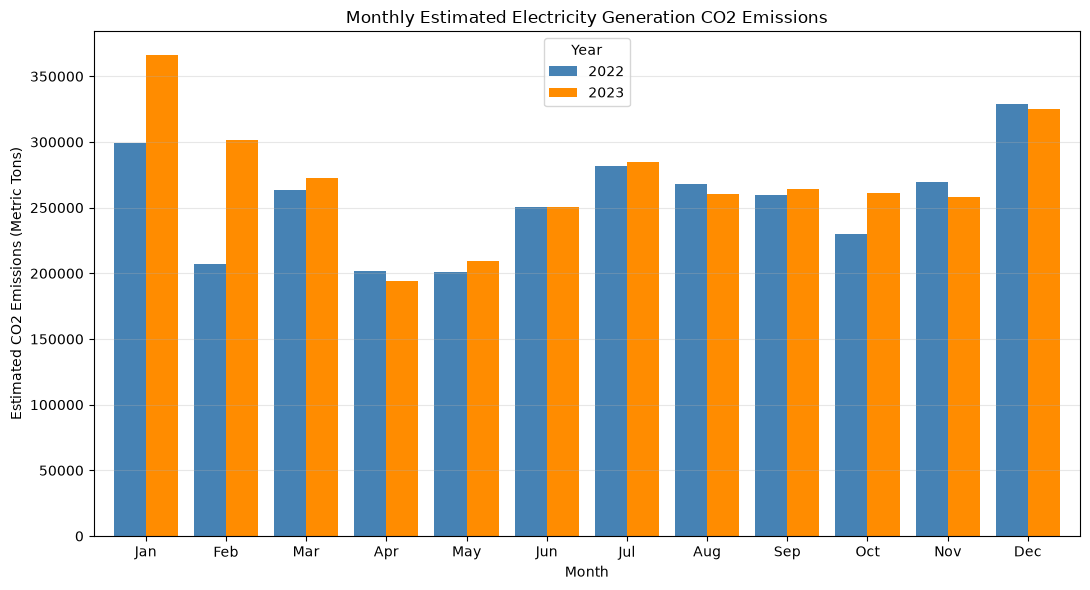

Monthly comparison logged to MLflow!
🏃 View run R3_Monthly_Emissions_Comparison at: http://10.0.100.20:5000/#/experiments/91/runs/10a688a6ed6441e59ac5597c1e4043df
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/91


In [13]:
# Step 13: Compare emissions month by month to see seasonal changes that annual totals hide.

# Extract month from the hourly dataset
hourly["month"] = pd.to_datetime(hourly["date"]).dt.month

# Calculate monthly emissions by year
monthly_emissions = (
    hourly.groupby(["year", "month"])["estimated_co2_kg"]
    .sum()
    .div(1000)
    .unstack("year")
)

# Create comparison graph
fig, ax = plt.subplots(figsize=(11, 6))

monthly_emissions.plot(
    kind="bar",
    ax=ax,
    color=["steelblue", "darkorange"],
    width=0.8
)

ax.set_title("Monthly Estimated Electricity Generation CO2 Emissions")
ax.set_xlabel("Month")
ax.set_ylabel("Estimated CO2 Emissions (Metric Tons)")
ax.set_xticklabels(
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    rotation=0
)
ax.legend(title="Year")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
display(fig)

# Log visualization and data to MLflow
with mlflow.start_run(run_name="R3_Monthly_Emissions_Comparison"):

    mlflow.log_figure(
        fig,
        "visualizations/monthly_emissions_comparison.png"
    )

    mlflow.log_table(
        monthly_emissions.reset_index(),
        "tables/monthly_emissions.json"
    )

    print("Monthly comparison logged to MLflow!")

plt.close(fig)

In [14]:
# Step 14: Inspect charging-session fields before relating EV charging activity to grid emissions.

# Load a small sample of the cleaned charging data
charging_sample = pd.read_csv(
    data_path / "charging_sessions_clean.csv",
    nrows=5
)

# Examine charging session structure
print("CHARGING SESSION COLUMNS")
print(charging_sample.columns.tolist())

print("\nCHARGING SESSION SAMPLE")
display(charging_sample)

# Examine hourly grid structure
print("\nHOURLY GRID COLUMNS")
print(hourly.columns.tolist())

print("\nHOURLY GRID SAMPLE")
display(hourly.head(5))

CHARGING SESSION COLUMNS
['session_id', 'vehicle_id', 'station_id', 'port_type', 'connector', 'start_time', 'end_time', 'kwh', 'home_or_public']

CHARGING SESSION SAMPLE


,session_id,vehicle_id,station_id,port_type,connector,start_time,end_time,kwh,home_or_public
0,CS00000001,EV05473,ST10239,dc fast,CCS,2022-09-01 07:51:00,2022-09-01 08:05:00,16.73,public
1,CS00000002,EV02752,ST10126,level 2,J1772,2022-09-01 09:50:00,2022-09-01 10:53:00,7.01,public
2,CS00000003,EV07339,H-EV07339,level 1,NACS,2022-09-01 14:30:00,2022-09-01 18:19:00,5.11,home
3,CS00000004,EV01210,H-EV01210,level 2,NACS,2022-09-01 14:30:00,2022-09-01 15:03:00,5.08,home
4,CS00000005,EV02900,H-EV02900,level 2,NACS,2022-09-01 15:45:00,2022-09-01 16:21:00,4.23,home



HOURLY GRID COLUMNS
['utc_time_at_end_of_hour', 'balancing_authority', 'demand_forecast_mwh', 'demand_mwh', 'net_generation', 'total_interchange', 'coal', 'natural_gas', 'nuclear', 'wind', 'solar', 'hydro', 'other', 'unit', 'grid_utc', 'timestamp', 'station_id', 'temp_f', 'heating_degree_hours', 'wind_speed_mph', 'relative_humidity', 'local_time', 'weather_utc', 'matching_utc', 'date', 'estimated_co2_kg', 'year', 'month']

HOURLY GRID SAMPLE


,utc_time_at_end_of_hour,balancing_authority,demand_forecast_mwh,demand_mwh,net_generation,total_interchange,coal,natural_gas,nuclear,wind,...,heating_degree_hours,wind_speed_mph,relative_humidity,local_time,weather_utc,matching_utc,date,estimated_co2_kg,year,month
0,2022-01-01 07:00,MCPA,634,643,643.0,0.0,284.0,0.0,211.0,106.0,...,24.9,5,72,2022-01-01 00:00:00,2022-01-01 06:00:00+00:00,2022-01-01 07:00:00+00:00,2022-01-01,286840.0,2022,1
1,2022-01-01 08:00,MCPA,633,642,642.0,0.0,282.0,0.0,210.0,106.0,...,26.9,4,83,2022-01-01 01:00:00,2022-01-01 07:00:00+00:00,2022-01-01 08:00:00+00:00,2022-01-01,284820.0,2022,1
2,2022-01-01 09:00,MCPA,639,641,640.0,0.0,286.0,0.0,209.0,106.0,...,28.1,4,88,2022-01-01 02:00:00,2022-01-01 08:00:00+00:00,2022-01-01 09:00:00+00:00,2022-01-01,288860.0,2022,1
3,2022-01-01 10:00,MCPA,638,646,646.0,0.0,302.0,0.0,210.0,94.0,...,29.6,4,93,2022-01-01 03:00:00,2022-01-01 09:00:00+00:00,2022-01-01 10:00:00+00:00,2022-01-01,305020.0,2022,1
4,2022-01-01 11:00,MCPA,645,654,654.0,0.0,332.0,0.0,211.0,73.0,...,30.2,4,86,2022-01-01 04:00:00,2022-01-01 10:00:00+00:00,2022-01-01 11:00:00+00:00,2022-01-01,335320.0,2022,1


In [15]:
# Step 15: Identify time-related grid fields so hourly observations can be grouped correctly.

# Identify the hour column
print("Time-related columns:")
print([
    col for col in hourly.columns
    if "time" in col.lower()
    or "hour" in col.lower()
    or "date" in col.lower()
])

# Check a few records
display(hourly.head(5))

Time-related columns:
['utc_time_at_end_of_hour', 'timestamp', 'heating_degree_hours', 'local_time', 'date']


,utc_time_at_end_of_hour,balancing_authority,demand_forecast_mwh,demand_mwh,net_generation,total_interchange,coal,natural_gas,nuclear,wind,...,heating_degree_hours,wind_speed_mph,relative_humidity,local_time,weather_utc,matching_utc,date,estimated_co2_kg,year,month
0,2022-01-01 07:00,MCPA,634,643,643.0,0.0,284.0,0.0,211.0,106.0,...,24.9,5,72,2022-01-01 00:00:00,2022-01-01 06:00:00+00:00,2022-01-01 07:00:00+00:00,2022-01-01,286840.0,2022,1
1,2022-01-01 08:00,MCPA,633,642,642.0,0.0,282.0,0.0,210.0,106.0,...,26.9,4,83,2022-01-01 01:00:00,2022-01-01 07:00:00+00:00,2022-01-01 08:00:00+00:00,2022-01-01,284820.0,2022,1
2,2022-01-01 09:00,MCPA,639,641,640.0,0.0,286.0,0.0,209.0,106.0,...,28.1,4,88,2022-01-01 02:00:00,2022-01-01 08:00:00+00:00,2022-01-01 09:00:00+00:00,2022-01-01,288860.0,2022,1
3,2022-01-01 10:00,MCPA,638,646,646.0,0.0,302.0,0.0,210.0,94.0,...,29.6,4,93,2022-01-01 03:00:00,2022-01-01 09:00:00+00:00,2022-01-01 10:00:00+00:00,2022-01-01,305020.0,2022,1
4,2022-01-01 11:00,MCPA,645,654,654.0,0.0,332.0,0.0,211.0,73.0,...,30.2,4,86,2022-01-01 04:00:00,2022-01-01 10:00:00+00:00,2022-01-01 11:00:00+00:00,2022-01-01,335320.0,2022,1


Possible timestamp columns: ['utc_time_at_end_of_hour', 'timestamp', 'heating_degree_hours']


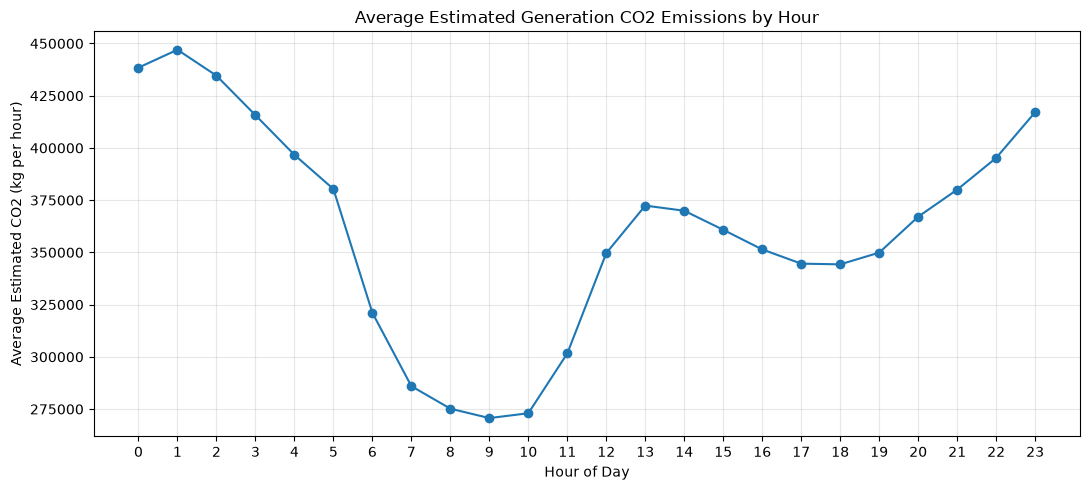

Hourly emissions graph logged to MLflow!
🏃 View run R3_Hourly_Grid_Emissions at: http://10.0.100.20:5000/#/experiments/91/runs/041a8a0c1a5947eb9a6580f428fcf887
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/91


In [16]:
# Step 16: Attempt to identify a timestamp automatically; this original cell may fail when several fields match.

# Find the hourly timestamp column
time_columns = [
    col for col in hourly.columns
    if "timestamp" in col.lower()
    or "datetime" in col.lower()
    or "hour" in col.lower()
]

print("Possible timestamp columns:", time_columns)

# Select the timestamp column
time_col = "utc_time_at_end_of_hour"

# Extract hour of day
hourly["hour_of_day"] = pd.to_datetime(
    hourly[time_col]
).dt.hour

# Average estimated emissions for each hour
hourly_emissions = hourly.groupby(
    "hour_of_day"
)["estimated_co2_kg"].mean()

# Create visualization
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    hourly_emissions.index,
    hourly_emissions.values,
    marker="o"
)

ax.set_title("Average Estimated Generation CO2 Emissions by Hour")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Average Estimated CO2 (kg per hour)")
ax.set_xticks(range(24))
ax.grid(alpha=0.3)

plt.tight_layout()
display(fig)

# Save graph to MLflow
with mlflow.start_run(run_name="R3_Hourly_Grid_Emissions"):
    mlflow.log_figure(
        fig,
        "visualizations/hourly_grid_emissions.png"
    )
    print("Hourly emissions graph logged to MLflow!")

plt.close(fig)

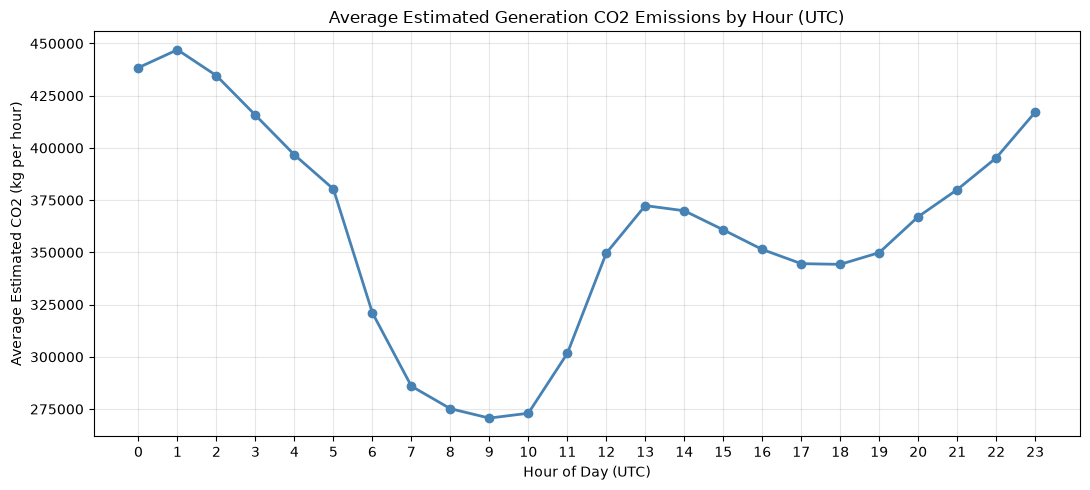

Hourly emissions graph logged to MLflow!
🏃 View run R3_Hourly_Grid_Emissions at: http://10.0.100.20:5000/#/experiments/91/runs/0d2870bbf3424917b898327fdc6dd512
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/91


In [17]:
# Step 17: Graph average generation emissions by UTC hour and log the visualization.

# Step 16: Average Hourly Grid Emissions Visualization

import pandas as pd
import matplotlib.pyplot as plt
import mlflow

# Use the correct timestamp column
time_col = "utc_time_at_end_of_hour"

# Convert timestamps and extract hour of day (UTC)
hourly["hour_of_day"] = pd.to_datetime(
    hourly[time_col], utc=True
).dt.hour

# Calculate average estimated emissions for each hour
hourly_emissions = (
    hourly.groupby("hour_of_day")["estimated_co2_kg"]
    .mean()
    .reindex(range(24))
)

# Create visualization
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    hourly_emissions.index,
    hourly_emissions.values,
    marker="o",
    color="steelblue",
    linewidth=2
)

ax.set_title("Average Estimated Generation CO2 Emissions by Hour (UTC)")
ax.set_xlabel("Hour of Day (UTC)")
ax.set_ylabel("Average Estimated CO2 (kg per hour)")
ax.set_xticks(range(24))
ax.grid(alpha=0.3)

plt.tight_layout()
display(fig)

# Log graph and data to MLflow
with mlflow.start_run(run_name="R3_Hourly_Grid_Emissions"):

    mlflow.log_figure(
        fig,
        "visualizations/hourly_grid_emissions.png"
    )

    mlflow.log_table(
        hourly_emissions.reset_index(name="average_co2_kg"),
        "tables/hourly_grid_emissions.json"
    )

    print("Hourly emissions graph logged to MLflow!")

plt.close(fig)

In [18]:
# Step 18: Inspect the large charging dataset with a small sample to avoid unnecessary memory use.

# Step 17: Inspect EV Charging Session Data

import pandas as pd

# Load a small sample first to avoid loading the entire large dataset
charging_sample = pd.read_csv(
    data_path / "charging_sessions_clean.csv",
    nrows=5
)

# Display available columns
print("CHARGING SESSION COLUMNS:")
for column in charging_sample.columns:
    print("-", column)

# Display sample records
print("\nSAMPLE CHARGING SESSIONS:")
display(charging_sample)

# Check dataset size without loading everything
with open(data_path / "charging_sessions_clean.csv",
          encoding="utf-8-sig") as f:
    row_count = sum(1 for _ in f) - 1

print(f"\nTotal charging sessions: {row_count:,}")

CHARGING SESSION COLUMNS:
- session_id
- vehicle_id
- station_id
- port_type
- connector
- start_time
- end_time
- kwh
- home_or_public

SAMPLE CHARGING SESSIONS:


,session_id,vehicle_id,station_id,port_type,connector,start_time,end_time,kwh,home_or_public
0,CS00000001,EV05473,ST10239,dc fast,CCS,2022-09-01 07:51:00,2022-09-01 08:05:00,16.73,public
1,CS00000002,EV02752,ST10126,level 2,J1772,2022-09-01 09:50:00,2022-09-01 10:53:00,7.01,public
2,CS00000003,EV07339,H-EV07339,level 1,NACS,2022-09-01 14:30:00,2022-09-01 18:19:00,5.11,home
3,CS00000004,EV01210,H-EV01210,level 2,NACS,2022-09-01 14:30:00,2022-09-01 15:03:00,5.08,home
4,CS00000005,EV02900,H-EV02900,level 2,NACS,2022-09-01 15:45:00,2022-09-01 16:21:00,4.23,home



Total charging sessions: 2,868,765


In [19]:
# Step 19: Find candidate charging start-time fields before grouping charging sessions by hour.

# Step 18: Identify Charging Start Times

# Get the available columns
columns = charging_sample.columns.tolist()

# Find columns related to charging start times
start_columns = [
    col for col in columns
    if "start" in col.lower()
    or "begin" in col.lower()
    or "plug_in" in col.lower()
]

print("Possible charging start-time columns:")
print(start_columns)

# Show sample values to verify the timestamp format
if start_columns:
    display(charging_sample[start_columns].head())
else:
    print("No obvious start-time column found.")
    print("Available columns:", columns)

Possible charging start-time columns:
['start_time']


,start_time
0,2022-09-01 07:51:00
1,2022-09-01 09:50:00
2,2022-09-01 14:30:00
3,2022-09-01 14:30:00
4,2022-09-01 15:45:00


Using charging start-time column: start_time


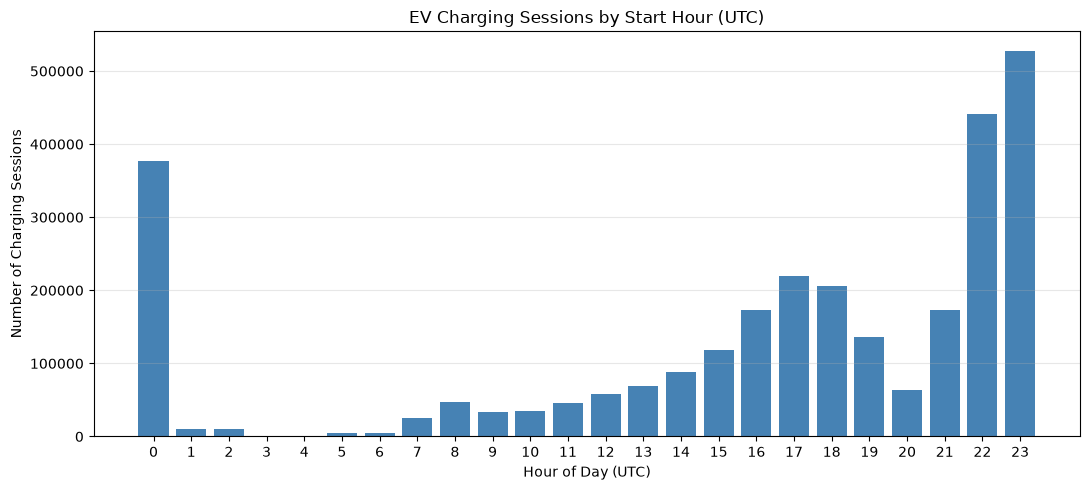

EV charging activity graph logged to MLflow!
🏃 View run R3_EV_Charging_By_Hour at: http://10.0.100.20:5000/#/experiments/91/runs/ee85ce02de0244789a5dd3e1640516cd
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/91


In [20]:
# Step 20: Count charging sessions by their start hour and log the daily activity pattern.

# Step 19: EV Charging Activity by Hour

import pandas as pd
import matplotlib.pyplot as plt
import mlflow

# Identify charging start-time column
possible_columns = [
    col for col in charging_sample.columns
    if "start" in col.lower()
    or "begin" in col.lower()
    or "plug_in" in col.lower()
]

if not possible_columns:
    raise ValueError(
        "No charging start-time column found. "
        f"Available columns: {charging_sample.columns.tolist()}"
    )

if len(possible_columns) != 1:
    raise ValueError(
        "Multiple possible start-time columns. "
        f"Please confirm which one to use: {possible_columns}"
    )

start_col = possible_columns[0]
print("Using charging start-time column:", start_col)

# Read only the timestamp column to conserve memory
charging_times = pd.read_csv(
    data_path / "charging_sessions_clean.csv",
    usecols=[start_col]
)

# Convert timestamps to datetime
charging_times["charging_start"] = pd.to_datetime(
    charging_times[start_col],
    errors="coerce",
    utc=True
)

# Count charging sessions by hour
charging_times["hour_of_day"] = (
    charging_times["charging_start"].dt.hour
)

charging_by_hour = (
    charging_times.groupby("hour_of_day")
    .size()
    .reindex(range(24), fill_value=0)
)

# Create visualization
fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    charging_by_hour.index,
    charging_by_hour.values,
    color="steelblue"
)

ax.set_title("EV Charging Sessions by Start Hour (UTC)")
ax.set_xlabel("Hour of Day (UTC)")
ax.set_ylabel("Number of Charging Sessions")
ax.set_xticks(range(24))
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
display(fig)

# Log to MLflow
with mlflow.start_run(run_name="R3_EV_Charging_By_Hour"):
    mlflow.log_figure(
        fig,
        "visualizations/ev_charging_by_hour.png"
    )

    mlflow.log_table(
        charging_by_hour.reset_index(name="session_count"),
        "tables/ev_charging_by_hour.json"
    )

    print("EV charging activity graph logged to MLflow!")

plt.close(fig)

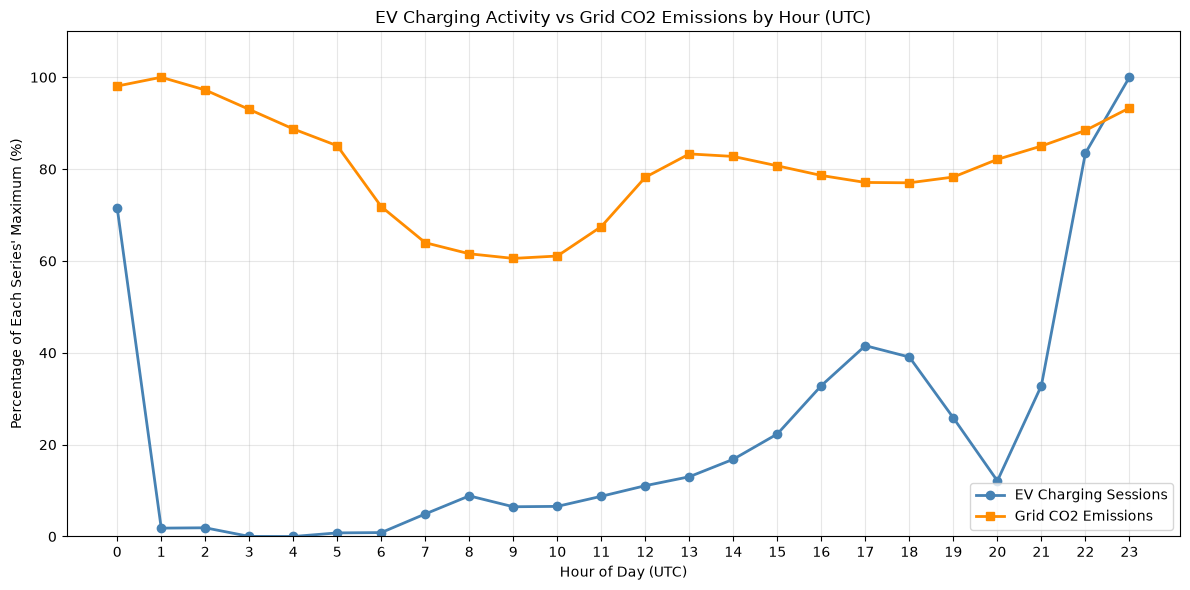

EV charging comparison logged to MLflow!
🏃 View run R3_EV_Charging_vs_Grid_Emissions at: http://10.0.100.20:5000/#/experiments/91/runs/5d71fd5ae09d4613a44ae2c1978167c0
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/91


In [21]:
# Step 21: Compare normalized charging-session counts with generation emissions; this is exploratory, not charging-attributable CO2.

# Step 20: EV Charging Activity vs Grid Emissions

import matplotlib.pyplot as plt
import mlflow
import pandas as pd

# Align both datasets to all 24 hours
hours = range(24)

charging = charging_by_hour.reindex(hours, fill_value=0)
emissions = hourly_emissions.reindex(hours)

# Normalize both series to compare their daily patterns
charging_normalized = charging / charging.max() * 100
emissions_normalized = emissions / emissions.max() * 100

# Create comparison graph
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    hours,
    charging_normalized,
    marker="o",
    linewidth=2,
    label="EV Charging Sessions",
    color="steelblue"
)

ax.plot(
    hours,
    emissions_normalized,
    marker="s",
    linewidth=2,
    label="Grid CO2 Emissions",
    color="darkorange"
)

ax.set_title("EV Charging Activity vs Grid CO2 Emissions by Hour (UTC)")
ax.set_xlabel("Hour of Day (UTC)")
ax.set_ylabel("Percentage of Each Series' Maximum (%)")
ax.set_xticks(range(24))
ax.set_ylim(0, 110)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
display(fig)

# Save comparison data
comparison = pd.DataFrame({
    "hour": list(hours),
    "charging_sessions": charging.values,
    "average_co2_kg": emissions.values,
    "charging_normalized": charging_normalized.values,
    "emissions_normalized": emissions_normalized.values
})

# Log results to MLflow
with mlflow.start_run(run_name="R3_EV_Charging_vs_Grid_Emissions"):

    mlflow.log_figure(
        fig,
        "visualizations/charging_vs_emissions.png"
    )

    mlflow.log_table(
        comparison,
        "tables/charging_vs_emissions.json"
    )

    print("EV charging comparison logged to MLflow!")

plt.close(fig)

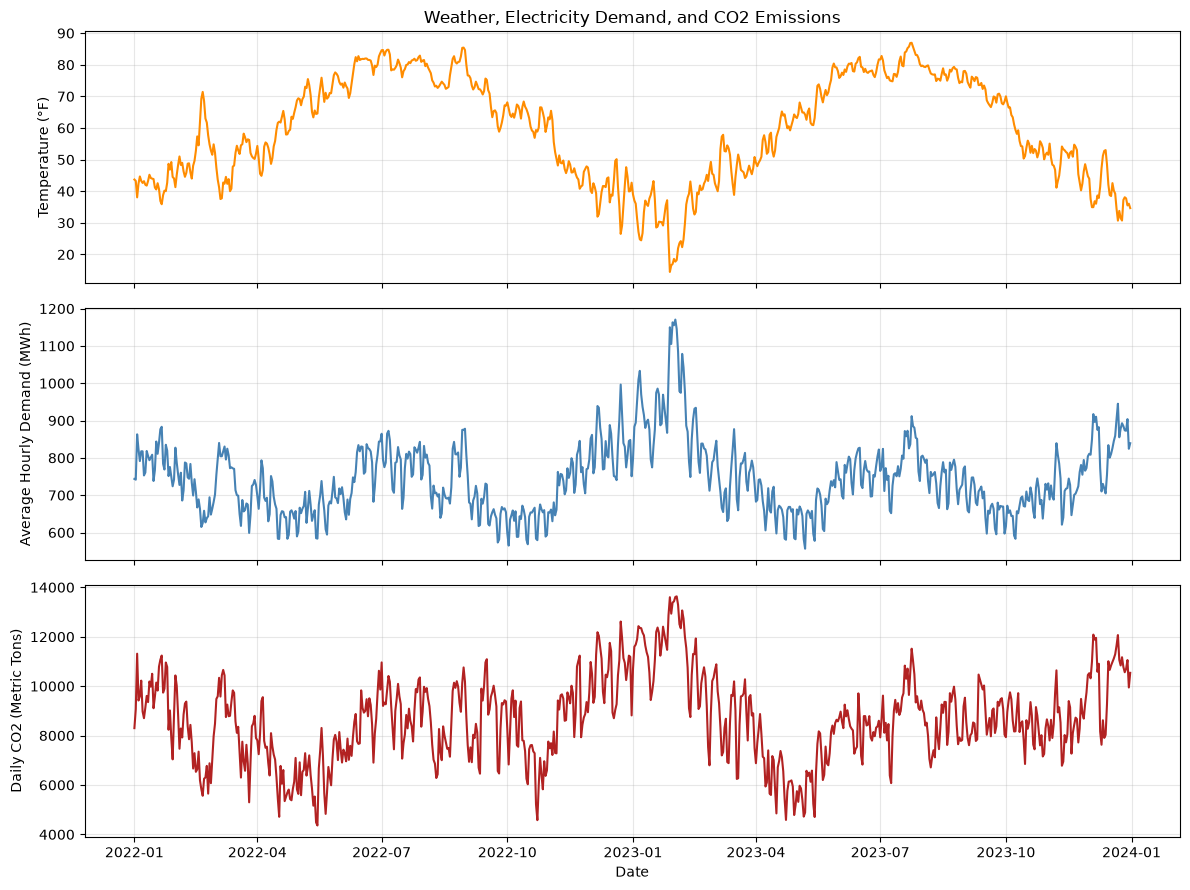

Weather, demand, and emissions graph logged to MLflow!
🏃 View run R3_Weather_Demand_Emissions at: http://10.0.100.20:5000/#/experiments/91/runs/3e1295e763e244f6b8a5b9581fac6b19
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/91


In [22]:
# Step 22: Compare temperature, demand, and generation emissions over time for research question 3.

# Step 21: Weather, Electricity Demand, and CO2 Emissions

import pandas as pd
import matplotlib.pyplot as plt
import mlflow

# Prepare daily data
weather_analysis = daily.copy()
weather_analysis["date"] = pd.to_datetime(weather_analysis["date"])

# Calculate daily total emissions from hourly records
hourly["date"] = pd.to_datetime(hourly["date"])

daily_emissions = (
    hourly.groupby("date")["estimated_co2_kg"]
    .sum()
    .reset_index()
)

# Merge daily emissions with weather and demand
weather_analysis = weather_analysis.merge(
    daily_emissions,
    on="date",
    how="inner"
)

# Create three graphs sharing the same date axis
fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 9),
    sharex=True
)

# Temperature
axes[0].plot(
    weather_analysis["date"],
    weather_analysis["temp_f"],
    color="darkorange"
)
axes[0].set_ylabel("Temperature (°F)")
axes[0].set_title("Weather, Electricity Demand, and CO2 Emissions")

# Electricity demand
axes[1].plot(
    weather_analysis["date"],
    weather_analysis["demand_mwh"],
    color="steelblue"
)
axes[1].set_ylabel("Average Hourly Demand (MWh)")

# Carbon emissions
axes[2].plot(
    weather_analysis["date"],
    weather_analysis["estimated_co2_kg"] / 1000,
    color="firebrick"
)
axes[2].set_ylabel("Daily CO2 (Metric Tons)")
axes[2].set_xlabel("Date")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
display(fig)

# Log visualization to MLflow
with mlflow.start_run(run_name="R3_Weather_Demand_Emissions"):

    mlflow.log_figure(
        fig,
        "visualizations/weather_demand_emissions.png"
    )

    mlflow.log_metric(
        "average_temperature_f",
        float(weather_analysis["temp_f"].mean())
    )

    mlflow.log_metric(
        "average_hourly_demand_mwh",
        float(weather_analysis["demand_mwh"].mean())
    )

    print("Weather, demand, and emissions graph logged to MLflow!")

plt.close(fig)

CORRELATION MATRIX:


,Temperature,Electricity Demand,CO2 Emissions
Temperature,1.000,-0.424,-0.436
Electricity Demand,-0.424,1.000,0.857
CO2 Emissions,-0.436,0.857,1.000


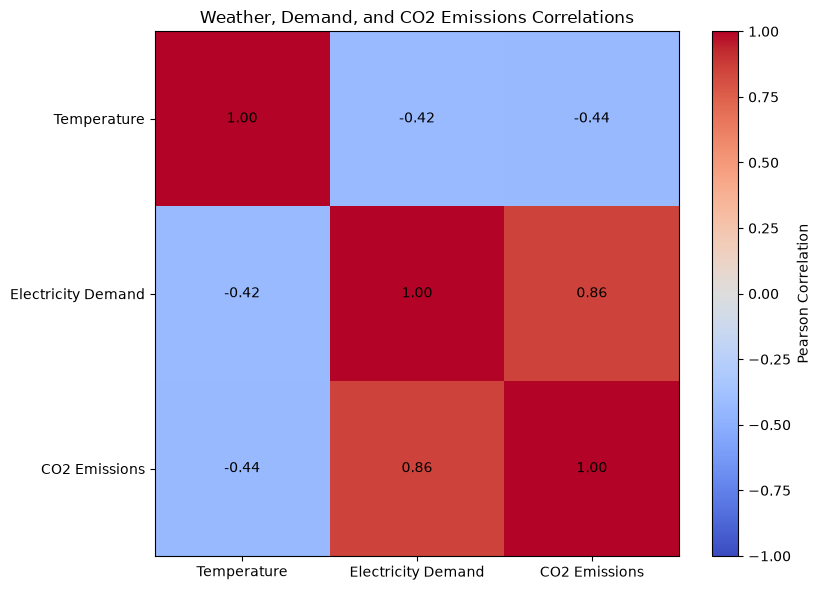

Correlation analysis logged to MLflow!
🏃 View run R3_Correlation_Analysis at: http://10.0.100.20:5000/#/experiments/91/runs/042e39e89d174353bae7eb5a1ac3f261
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/91


In [23]:
# Step 23: Calculate correlations to quantify linear relationships between weather, demand, and emissions.

# Step 22: Correlation Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import mlflow

# Select variables for correlation analysis
correlation_data = weather_analysis[
    ["temp_f", "demand_mwh", "estimated_co2_kg"]
].copy()

# Rename columns for readability
correlation_data.columns = [
    "Temperature",
    "Electricity Demand",
    "CO2 Emissions"
]

# Calculate Pearson correlations
correlation_matrix = correlation_data.corr(method="pearson")

print("CORRELATION MATRIX:")
display(correlation_matrix.round(3))

# Create correlation heatmap
fig, ax = plt.subplots(figsize=(8, 6))

heatmap = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

# Add labels
ax.set_xticks(range(3))
ax.set_yticks(range(3))

ax.set_xticklabels(correlation_matrix.columns)
ax.set_yticklabels(correlation_matrix.columns)

# Display correlation values
for i in range(3):
    for j in range(3):
        ax.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            color="black"
        )

ax.set_title("Weather, Demand, and CO2 Emissions Correlations")

plt.colorbar(heatmap, ax=ax, label="Pearson Correlation")
plt.tight_layout()
display(fig)

# Log results to MLflow
with mlflow.start_run(run_name="R3_Correlation_Analysis"):

    mlflow.log_figure(
        fig,
        "visualizations/correlation_heatmap.png"
    )

    mlflow.log_table(
        correlation_matrix.reset_index(),
        "tables/correlation_matrix.json"
    )

    mlflow.log_metric(
        "temperature_emissions_correlation",
        float(correlation_matrix.loc["Temperature", "CO2 Emissions"])
    )

    mlflow.log_metric(
        "demand_emissions_correlation",
        float(correlation_matrix.loc["Electricity Demand", "CO2 Emissions"])
    )

    print("Correlation analysis logged to MLflow!")

plt.close(fig)

In [24]:
# Step 24: Summarize the main numerical results and save summary tables locally and in MLflow.

# Step 23: Final R3 Summary Statistics

import pandas as pd
import mlflow

# Summary statistics for daily weather, demand, and emissions
summary_columns = [
    "temp_f",
    "demand_mwh",
    "estimated_co2_kg"
]

summary_stats = (
    weather_analysis[summary_columns]
    .describe()
    .round(2)
)

summary_stats.columns = [
    "Temperature (F)",
    "Average Hourly Demand (MWh)",
    "Daily Estimated CO2 (kg)"
]

print("R3 SUMMARY STATISTICS")
display(summary_stats)

# Annual emissions comparison
annual_summary = pd.DataFrame({
    "Year": [2022, 2023],
    "Estimated CO2 (Metric Tons)": [
        yearly_emissions_tons.loc[2022],
        yearly_emissions_tons.loc[2023]
    ]
})

print("\nANNUAL EMISSIONS COMPARISON")
display(annual_summary.round(2))

print(f"\n2022 to 2023 emissions change: {change:.2f}%")

# Save summary statistics to CSV files
summary_stats.to_csv(
    data_path / "r3_summary_statistics.csv"
)

annual_summary.to_csv(
    data_path / "r3_annual_emissions_summary.csv",
    index=False
)

# Log results to MLflow
with mlflow.start_run(run_name="R3_Final_Summary_Statistics"):

    mlflow.log_table(
        summary_stats.reset_index(),
        "tables/r3_summary_statistics.json"
    )

    mlflow.log_table(
        annual_summary,
        "tables/r3_annual_emissions_summary.json"
    )

    mlflow.log_metric(
        "annual_emissions_change_percent",
        float(change)
    )

    mlflow.log_metric(
        "total_daily_records",
        len(weather_analysis)
    )

    print("\nSummary statistics logged to MLflow!")

R3 SUMMARY STATISTICS


,Temperature (F),Average Hourly Demand (MWh),Daily Estimated CO2 (kg)
count,730.00,730.00,730.00
mean,59.52,744.83,8642839.44
std,16.39,96.82,1744763.24
min,14.47,556.58,4361450.00
25%,45.85,670.92,7451645.00
50%,60.28,735.56,8619795.00
75%,74.84,802.86,9713780.00
max,86.95,1170.62,13633510.00



ANNUAL EMISSIONS COMPARISON


,Year,Estimated CO2 (Metric Tons)
0,2022,3061445.31
1,2023,3247827.48



2022 to 2023 emissions change: 6.09%

Summary statistics logged to MLflow!
🏃 View run R3_Final_Summary_Statistics at: http://10.0.100.20:5000/#/experiments/91/runs/7db2508620f4460581870703092c3c29
🧪 View experiment at: http://10.0.100.20:5000/#/experiments/91


In [25]:
# Step 25: Check which R3 runs were recorded in MLflow and whether their status is finished.

# Step 24: Verify R3 MLflow Runs

import mlflow
import pandas as pd

# Connect to MLflow
mlflow.set_tracking_uri(MLFLOW_SERVER)

# Find our experiment
experiment = mlflow.get_experiment_by_name(EXPERIMENT)

if experiment is None:
    print("Experiment not found:", EXPERIMENT)

else:
    # Retrieve all runs
    runs = mlflow.search_runs(
        experiment_ids=[experiment.experiment_id],
        max_results=1000
    )

    # Filter for R3 runs
    r3_runs = runs[
        runs["tags.mlflow.runName"]
        .fillna("")
        .str.startswith("R3_")
    ].copy()

    # Display relevant information
    results = r3_runs[
        [
            "tags.mlflow.runName",
            "status",
            "start_time",
            "run_id"
        ]
    ].sort_values(
        "start_time",
        ascending=True
    )

    print("R3 MLFLOW RUNS")
    display(results)

    print("\nTotal R3 runs:", len(results))

    print(
        "Finished runs:",
        (results["status"] == "FINISHED").sum()
    )

R3 MLFLOW RUNS


,tags.mlflow.runName,status,start_time,run_id
31,R3_2022_vs_2023_Emissions,FINISHED,2026-11-05 00:44:04.668+00:00,6c35736db619467e84eb5a20c455b9f9
30,R3_2022_vs_2023_Emissions,FINISHED,2026-11-05 00:44:42.198+00:00,ca20203fa7f6419097047db25d487225
29,R3_Monthly_Emissions_Comparison,FINISHED,2026-11-05 00:44:46.720+00:00,f49d0b6298ca4f388d13415fc4c14658
28,R3_Monthly_Emissions_Comparison,FINISHED,2026-11-05 00:45:14.411+00:00,a12640e74d524f0eb750cff7970522a7
27,R3_Hourly_Grid_Emissions,FINISHED,2026-11-05 00:50:46.622+00:00,b72c81c83a6543fa8b6abf1a75322cf1
26,R3_2022_vs_2023_Emissions,FINISHED,2026-11-05 00:51:47.889+00:00,c2e920d3f19a450f87b13f80794e81a6
25,R3_Monthly_Emissions_Comparison,RUNNING,2026-11-05 00:51:52.415+00:00,768e1143dd31400c8645f84213d225a1
24,R3_2022_vs_2023_Emissions,FINISHED,2026-11-05 00:52:06.808+00:00,30d36f1fd2954afaa7914d4faa7df381
23,R3_Monthly_Emissions_Comparison,FINISHED,2026-11-05 00:52:11.399+00:00,fafe1c126f9e4583a586c7a8f1e465bb
22,R3_Hourly_Grid_Emissions,FINISHED,2026-11-05 00:52:18.521+00:00,c41ee61c920f402ebb80b7c6ee6afa31



Total R3 runs: 32
Finished runs: 31
